In [13]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model

In [14]:
model = load_model(r"C:\ML\traffic_sign_cnn.keras")

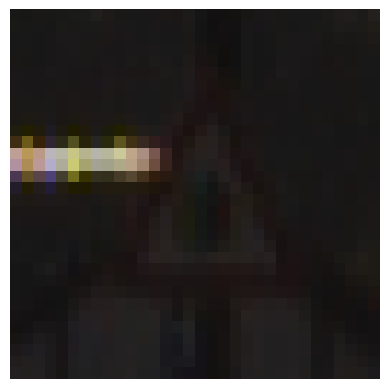

In [15]:
img_path = r"C:\ML\Train\30\00030_00000_00000.png"

img = cv2.imread(img_path)

if img is not None:
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (32, 32))
    plt.imshow(img)
    plt.axis("off")
    plt.show()
else:
    print("Image not found. Check the file path.")

In [16]:
prediction = model.predict(
    img.reshape(1, 32, 32, 3).astype("float32") / 255.0,
    verbose=0
)

class_id = np.argmax(prediction)

print("Predicted Class:", class_id)
print("Confidence:", round(float(np.max(prediction)) * 100, 2), "%")

Predicted Class: 30
Confidence: 98.16 %


In [17]:
sign_names = [
    "Speed limit 20", "Speed limit 30", "Speed limit 50",
    "Speed limit 60", "Speed limit 70", "Speed limit 80",
    "End of speed limit 80", "Speed limit 100", "Speed limit 120",
    "No passing", "No passing for vehicles over 3.5 tons",
    "Right-of-way at intersection", "Priority road", "Yield",
    "Stop", "No vehicles", "Vehicles over 3.5 tons prohibited",
    "No entry", "General caution", "Dangerous curve left",
    "Dangerous curve right", "Double curve", "Bumpy road",
    "Slippery road", "Road narrows", "Road work", "Traffic signals",
    "Pedestrians", "Children crossing", "Bicycles crossing",
    "Beware of ice/snow", "Wild animals crossing",
    "End of speed limit 80", "Turn right ahead", "Turn left ahead",
    "Ahead only", "Go straight or right", "Go straight or left",
    "Keep right", "Keep left", "Roundabout mandatory",
    "End of no passing",
    "End of no passing for vehicles over 3.5 tons"
]

print("Traffic Sign:", sign_names[class_id])

Traffic Sign: Beware of ice/snow


In [18]:
print("Predicted Traffic Sign:", sign_names[class_id])
print("Model Confidence:", f"{float(np.max(prediction)) * 100:.2f}%")

Predicted Traffic Sign: Beware of ice/snow
Model Confidence: 98.16%


Enter the full image path:  C:\ML\Train\30\00030_00000_00000.png


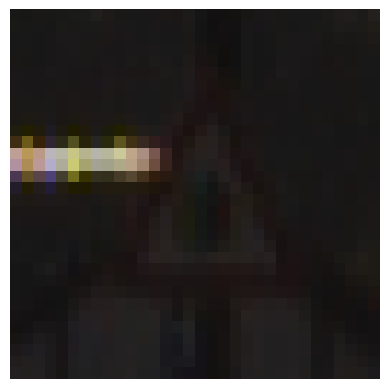

Traffic Sign: Beware of ice/snow
Confidence: 98.16 %


In [21]:
img_path = input("Enter the full image path: ")

img = cv2.imread(img_path)

if img is None:
    print("Image not found. Check the path.")
else:
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (32, 32))
    img = img.astype("float32") / 255.0

    prediction = model.predict(img.reshape(1, 32, 32, 3), verbose=0)
    class_id = np.argmax(prediction)

    plt.imshow(img)
    plt.axis("off")
    plt.show()

    print("Traffic Sign:", sign_names[class_id])
    print("Confidence:", round(float(np.max(prediction)) * 100, 2), "%")

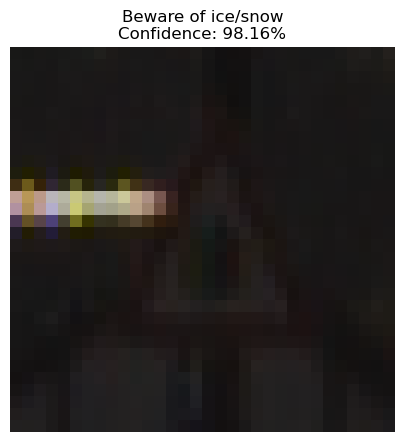

In [22]:
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.title(f"{sign_names[class_id]}\nConfidence: {np.max(prediction) * 100:.2f}%")
plt.axis("off")
plt.show()

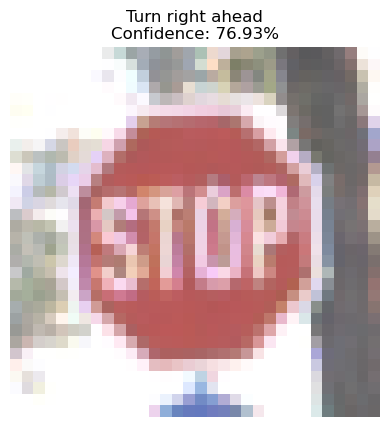

In [23]:
img_path = r"C:\ML\Train\14\00014_00000_00000.png"

img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img = cv2.resize(img, (32, 32))

prediction = model.predict(
    img.reshape(1, 32, 32, 3).astype("float32") / 255.0,
    verbose=0
)

class_id = np.argmax(prediction)

plt.imshow(img)
plt.title(f"{sign_names[class_id]}\nConfidence: {np.max(prediction) * 100:.2f}%")
plt.axis("off")
plt.show()

In [24]:
for class_no in [0, 1, 14, 17, 33]:
    img_path = os.path.join(
        r"C:\ML\Train", str(class_no),
        f"{class_no:05d}_00000_00000.png"
    )

    img = cv2.imread(img_path)

    if img is not None:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (32, 32))

        prediction = model.predict(
            img.reshape(1, 32, 32, 3).astype("float32") / 255.0,
            verbose=0
        )

        predicted_class = np.argmax(prediction)

        print(
            "Actual:", sign_names[class_no],
            "| Predicted:", sign_names[predicted_class],
            "| Confidence:", round(float(np.max(prediction)) * 100, 2), "%"
        )

Actual: Speed limit 20 | Predicted: Speed limit 70 | Confidence: 92.34 %
Actual: Speed limit 30 | Predicted: Speed limit 30 | Confidence: 99.97 %
Actual: Stop | Predicted: Turn right ahead | Confidence: 76.93 %
Actual: No entry | Predicted: No entry | Confidence: 35.5 %
Actual: Turn right ahead | Predicted: Priority road | Confidence: 89.22 %


In [27]:
X = []
y = []

for class_no in range(43):
    folder = os.path.join(r"C:\ML\Train", str(class_no))

    for file in os.listdir(folder):
        if file.endswith((".png", ".jpg", ".ppm")):
            img_path = os.path.join(folder, file)
            img = cv2.imread(img_path)

            if img is not None:
                img = cv2.resize(img, (32, 32))
                X.append(img)
                y.append(class_no)

X = np.array(X, dtype="float32") / 255.0
y = np.array(y)

print(X.shape, y.shape)

(39209, 32, 32, 3) (39209,)


In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

Test Accuracy: 99.31 %


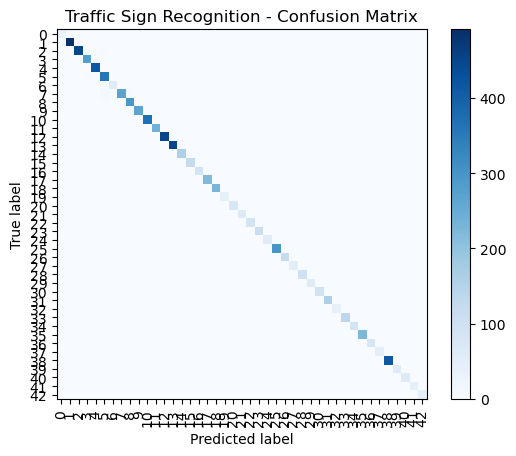

In [29]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, cmap="Blues",
    xticks_rotation="vertical",
    include_values=False
)

plt.title("Traffic Sign Recognition - Confusion Matrix")
plt.show()